# 05 · Fenómeno 6 (elección): la calidad del dato como hallazgo

¿Los faltantes, centinelas y valores imposibles se distribuyen al azar o siguen al
proceso? Reglas de depuración declaradas (L1–L10) con su bitácora. Figura 5.

In [1]:
import sys
sys.path.insert(0, "..")  # para importar src/

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.poblacion import preparar, poblacion
from src.depuracion import tabla_reglas, bitacora, columnas_sin_variacion, COLUMNAS_SPRAYS
from src.visualizacion import estilo, guardar, AZUL, NARANJA, ROJO, GRIS

df, d = preparar()
estilo()

## 1. Reglas de depuración declaradas y su bitácora

In [3]:
print(tabla_reglas().to_string(index=False))
print("\nBitácora (rollos tocados por cada regla y relación con el dictamen):")
print(bitacora(df).round(3).to_string(index=False))

 id                         columna                          condición                       acción                                                                                                  motivo
 L1                   Corona Salida                 ≤ 0 µm o > 1000 µm             NaN en corona_um La corona de banda caliente es positiva y del orden de decenas a cientos de µm; ±8,700 µm es imposible.
 L2              Acuñamiento Salida                   |valor| > 500 µm               NaN en cuna_um                                                Misma lógica que L1; la cuña típica es de decenas de µm.
 L3     Temperatura Descarga Salida                             ≤ 0 °C       NaN en temp_descarga_l                                                        Centinela: un planchón no sale del horno a 0 °C.
 L4             Temp Enrollado Real                             ≤ 0 °C NaN en temp_enrollado_real_l                                                           Centinela de medición falt

## 2. Columnas sin información

In [4]:
vacias, constantes = columnas_sin_variacion(df)
print(f"\nColumnas 100 % vacías: {len(vacias)} | constantes: {len(constantes)}")


Columnas 100 % vacías: 42 | constantes: 38


## 3. Mecanismo del faltante de corona (el faltante sigue al proceso, no al calendario)

In [5]:
sin = df["Corona Salida"].isna()
ret = df["Dictamen"].eq("RETENIDO")
print(f"\nCorona faltante: {100 * sin.mean():.1f} % de los rollos")
print(f"P(RETENIDO | sin corona) = {ret[sin].mean():.2f} vs. P(RETENIDO | con corona) = {ret[~sin].mean():.2f}")
print(f"P(MAL PERFIL | sin corona) = {df.loc[sin, 'def_mal_perfil'].mean():.2f} "
      f"vs. {df.loc[~sin, 'def_mal_perfil'].mean():.2f}")
loop = df["Tiempo de Resp. de Looper 1 (min)"].isna()
print(f"Rollos sin respuesta de looper que tampoco tienen corona: {100 * sin[loop].mean():.0f} % "
      f"(sin looper: {100 * loop.mean():.1f} % de los rollos)")

# ¿Y el faltante "grande" de % Uso Modelo?
sin_um = df["% Uso Modelo"].isna()
print(f"\n% Uso Modelo faltante: {100 * sin_um.mean():.1f} % | "
      f"P(RETENIDO | falta) = {ret[sin_um].mean():.2f} vs. {ret[~sin_um].mean():.2f} → ignorable")


Corona faltante: 2.3 % de los rollos
P(RETENIDO | sin corona) = 0.68 vs. P(RETENIDO | con corona) = 0.50
P(MAL PERFIL | sin corona) = 0.99 vs. 0.04
Rollos sin respuesta de looper que tampoco tienen corona: 91 % (sin looper: 0.2 % de los rollos)

% Uso Modelo faltante: 27.4 % | P(RETENIDO | falta) = 0.50 vs. 0.50 → ignorable


## 4. Figura 5: el faltante es estable en el tiempo pero informativo del resultado

/Users/macbookpro/Desktop/ternium/outputs/figuras/fig5_faltantes.png


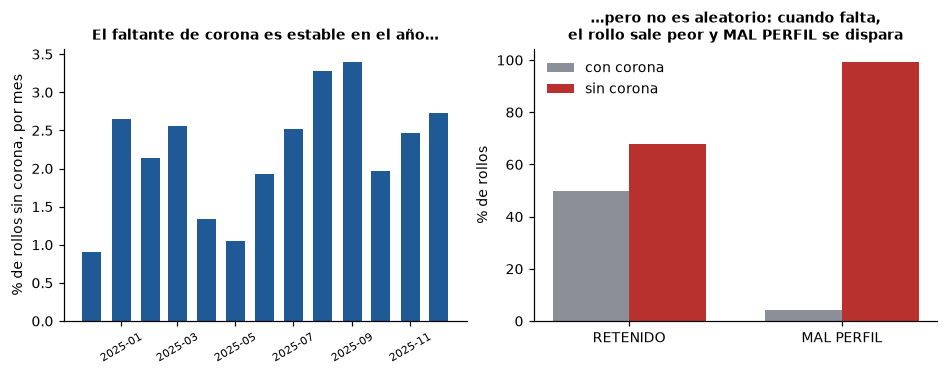

In [6]:
por_mes = df.groupby("mes").agg(falta=("Corona Salida", lambda s: 100 * s.isna().mean()))
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.3))
axes[0].bar(por_mes.index, por_mes["falta"], width=20, color=AZUL)
axes[0].set_title("El faltante de corona es estable en el año…", fontsize=9)
axes[0].set_ylabel("% de rollos sin corona, por mes")
axes[0].tick_params(axis="x", labelsize=7, rotation=30)
grupos = ["RETENIDO", "MAL PERFIL"]
con_dato = [ret[~sin].mean() * 100, df.loc[~sin, "def_mal_perfil"].mean() * 100]
sin_dato = [ret[sin].mean() * 100, df.loc[sin, "def_mal_perfil"].mean() * 100]
x = np.arange(2)
axes[1].bar(x - 0.18, con_dato, width=0.36, label="con corona", color=GRIS)
axes[1].bar(x + 0.18, sin_dato, width=0.36, label="sin corona", color=ROJO)
axes[1].set_xticks(x, grupos)
axes[1].set_ylabel("% de rollos")
axes[1].legend()
axes[1].set_title("…pero no es aleatorio: cuando falta,\nel rollo sale peor y MAL PERFIL se dispara", fontsize=9)
print(guardar(fig, "fig5_faltantes"))

## 5. Información perdida en la exportación y variantes de captura

In [7]:
spray = pd.to_numeric(df[COLUMNAS_SPRAYS[0]], errors="coerce").dropna()
magnitud = np.log10(spray[spray > 0]).median()
signif = spray.astype(str).str.replace(".", "").str.split("e").str[0].str.rstrip("0").str.len()
print(f"\nPatrones de sprays guardados como números: magnitud mediana 10^{magnitud:.0f} con "
      f"~{signif.median():.0f} dígitos significativos (la precisión de un float: "
      f"el patrón de encendido/apagado es irrecuperable)")
print(f"Variantes de captura en Norma: {df['Norma'].nunique()} textos → {df['norma_l'].nunique()} normas")


Patrones de sprays guardados como números: magnitud mediana 10^83 con ~13 dígitos significativos (la precisión de un float: el patrón de encendido/apagado es irrecuperable)
Variantes de captura en Norma: 49 textos → 47 normas
